# Trabalhando no domínio da frequência

Nesta aula, você aprenderá:
* Como transformar um sinal do domínio do tempo para o domínio da frequência.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

In [10]:
# -- Criar um sinal composto por três ondas senoidais

# -- Definir a frequência de amostragem e o vetor de tempo
fs = 2000  # Hz
time = np.arange(0,5,1/fs)

# -- Definir três ondas senoidais
sine1 = np.sin(2*np.pi*190*time)
sine2 = np.sin(2*np.pi*220*time)
sine3 = np.sin(2*np.pi*310*time)

# -- Somar as componentes
data = sine1 + sine2 + sine3

print(200/fs)
print("Número de amostras, N = fs * dt =", len(time))
print("Duração total, T(s) = N * dt :", len(time) / fs) 

0.1
Número de amostras, N = fs * dt = 10000
Duração total, T(s) = N * dt : 5.0


Text(0.5, 1.0, 'Sinal no domínio do tempo')

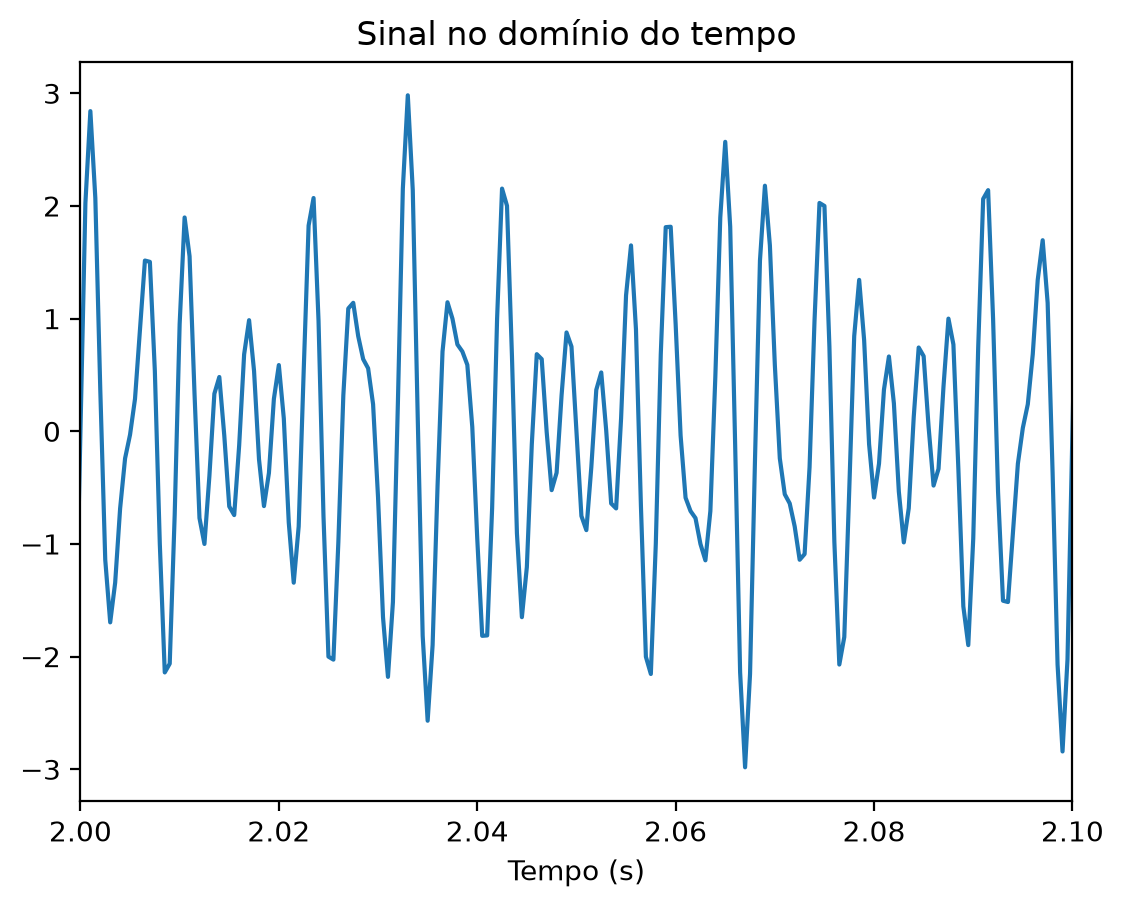

In [5]:
# -- Representar graficamente o sinal no domínio do tempo
plt.plot(time, data)
plt.xlim(2, 2.1)
plt.xlabel('Tempo (s)')
plt.title('Sinal no domínio do tempo')

A função cria uma janela de Tukey, utilizada para reduzir as descontinuidades nas extremidades de um sinal antes de calcular a FFT.

O argumento len(data) informa o número de amostras. Assim, a janela possui exatamente o mesmo tamanho do vetor data.

Matematicamente, a aplicação da janela corresponde a multiplicar cada amostra do sinal pela amostra correspondente da janela:

$$x_{janela} = w[n] x[n]$$

**Por que fazer isso?** 

Porque a FFT trata o trecho analisado como se ele se repetisse periodicamente. Se os valores no início e no fim forem diferentes, essa repetição pode introduzir descontinuidades artificiais.

Essas descontinuidades produzem o chamado vazamento espectral (spectral leakage), espalhando energia por frequências próximas. A janela reduz esse efeito, embora também modifique as amplitudes e alargue os picos espectrais.

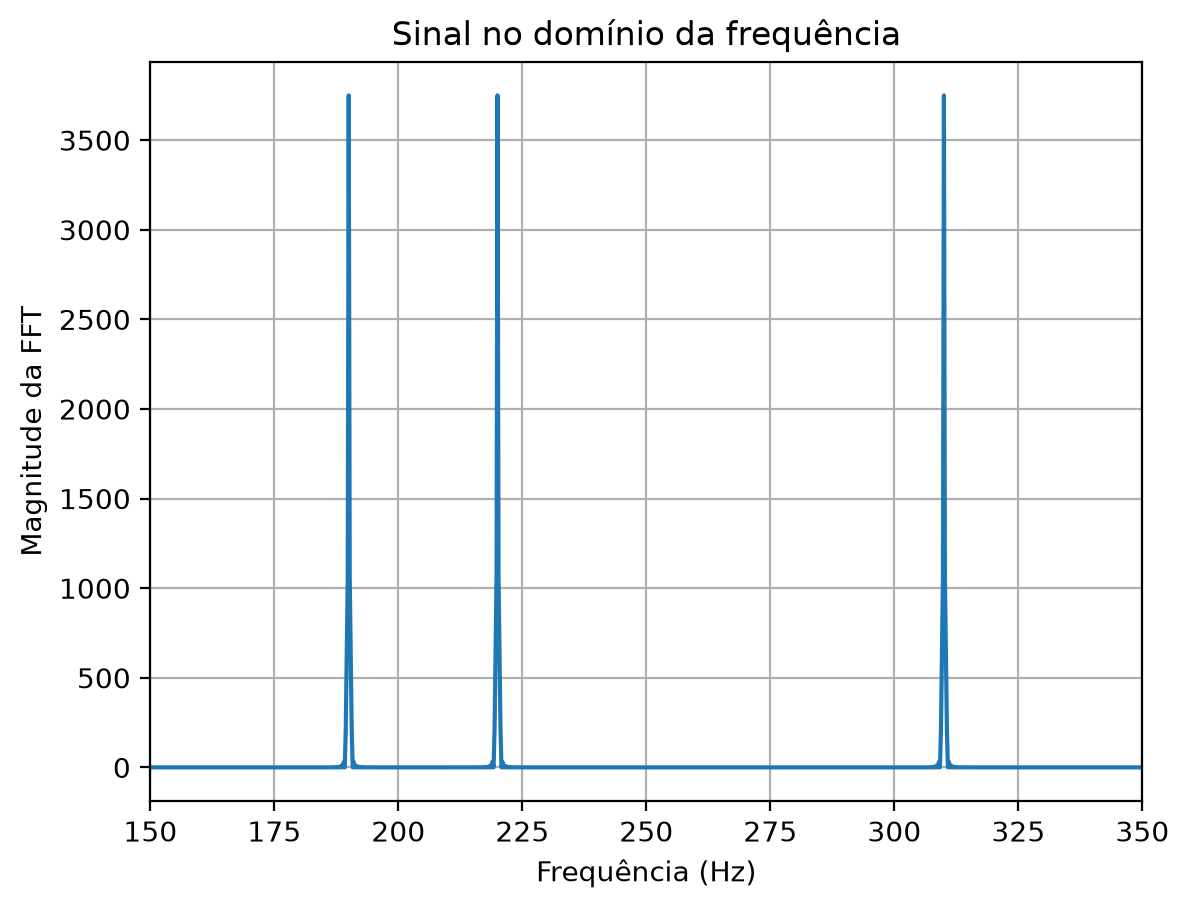

In [11]:
# Importar o módulo de processamento de sinais
from scipy import signal

# Número de amostras e intervalo entre amostras
N = len(data)
dt = 1 / fs

# Criar uma janela de Tukey
window = signal.windows.tukey(N)

# Aplicar a janela aos dados
data_window = window * data

# Calcular a FFT dos dados reais
data_freq = np.fft.rfft(data_window)

# Construir o vetor de frequências em Hz
frequencies = np.fft.rfftfreq(N, d=dt)

# Representar a magnitude da FFT
plt.plot(frequencies, np.abs(data_freq))
plt.xlim(150, 350)
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude da FFT')
plt.title('Sinal no domínio da frequência')
plt.grid()

## Transformada Rápida de Fourier de um sinal real.

A função rfft calcula a Transformada Rápida de Fourier de um sinal real.

$$ X[k] = \sum_{n=0}^{N-1} x[n] e^{-i2\pi k n}/N$$

onde:
- $x[n]$ representa as amostras do sinal no domínio do tempo.
- $N$ é o número total de amostras.
- $k$ identifica uma frequência discreta.
- $X[k]$ é um número complexo que contém informações de amplitude e fase.

A função `np.fft.fft()` retorna componentes associadas às frequências positivas e negativas. Por isso, `np.fft.rfft()` retorna apenas as componentes de frequência não negativa, evitando informações redundantes.

Por exemplo, para $N=10000$ amostras:
- np.fft.fft(data) retorna 10000 valores;
- np.fft.rfft(data) retorna 5001 valores.

O resultado armazenado em data_freq é um vetor de números complexos. Assim, `np.abs(data_freq)` obtém o módulo desses números, isto é, a magnitude das componentes espectrais.

A função `np.fft.rfftfreq()` constrói o vetor de frequências correspondente aos valores calculados pela `np.fft.rfft()`. 

É importante distinguir as funções:
- rfft() calcula as componentes espectrais do sinal.
- rfftfreq() informa a frequência física associada a cada componente.

As frequências discretas são calculadas por:

$$f_k = k \frac{f_s}{N}$$

em que $$k=0,1,\ldots,\lfloor N/2\rfloor$$


## Exemplo com os parâmetros do notebook
Considere:
$$
f_s=2000\,\mathrm{Hz}, \qquad \Delta t=5\,\mathrm{s}.
$$

O número de amostras será:
$$
N=f_s\Delta t=10000.
$$

O espaçamento entre as frequências calculadas é:
$$
\delta f=\frac{f_s}{N}=\frac{2000}{10000}
$$

$$
\boxed{\delta f=0{,}2\,\mathrm{Hz}}
$$

Portanto, o vetor de frequências contém:

$$[0.0, 0.2, 0.4, 0.6, 0.8, ..., 999.8, 1000.0]$$


O valor máximo corresponde à frequência de Nyquist:

$$
f_N=\frac{2000}{2}=1000\,\mathrm{Hz}.
$$

Finalmente, quando não fornecemos o intervalo entre amostras, o NumPy considera $d=1$. Assim, as frequências são inicialmente expressas em ciclos por amostra.

Multiplicar por $f_s$ converte esses valores para hertz.


Text(0.5, 1.0, 'Sinal no domínio do tempo')

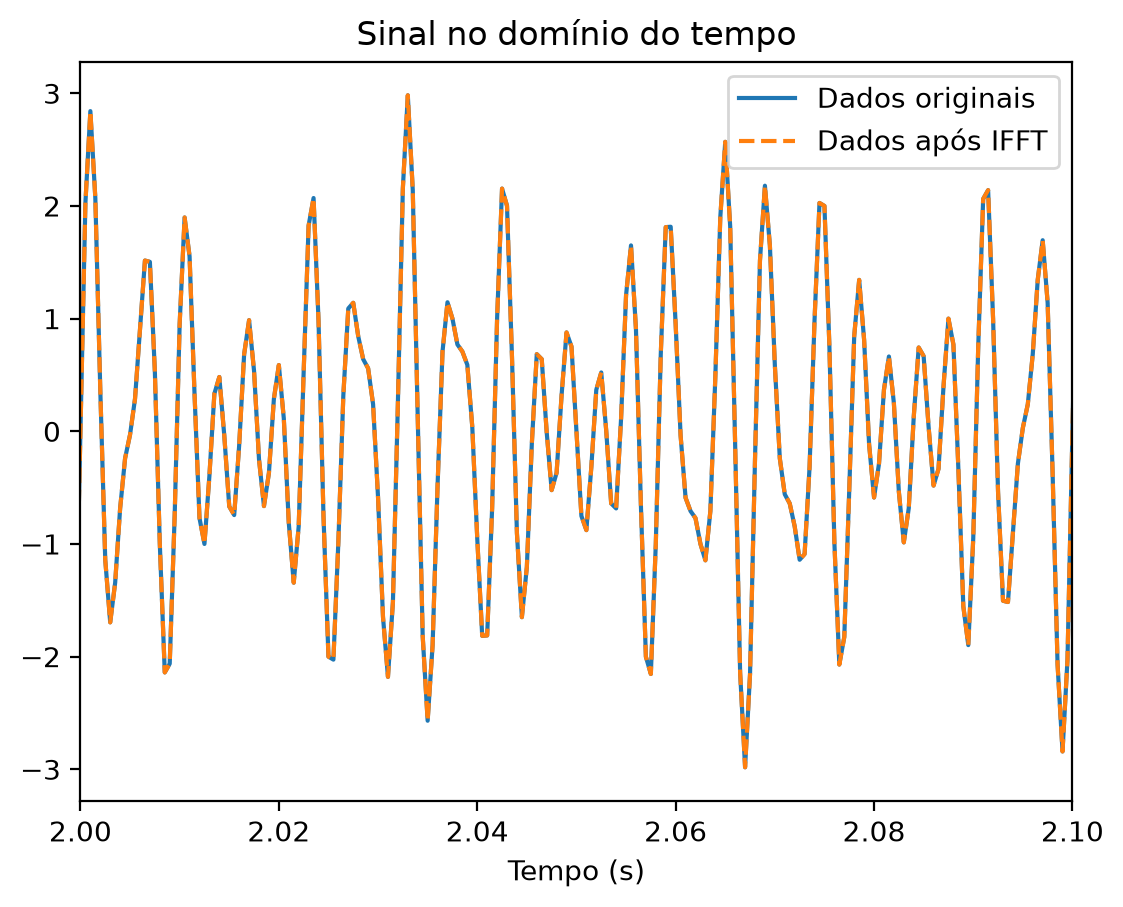

In [12]:
# -- Por fim, podemos voltar ao domínio do tempo
# -- usando a Transformada Inversa de Fourier (IFFT)

data_after_ifft = np.fft.irfft(data_freq)

plt.plot(time, data, label='Dados originais')
plt.plot(time,data_after_ifft, '--', label='Dados após IFFT')
plt.xlim(2, 2.1)
plt.xlabel('Tempo (s)')
plt.legend(loc=1)
plt.title('Sinal no domínio do tempo')

# Questões de verificação

1. Observe o código abaixo do comentário "Definir três ondas senoidais". Quais são as frequências das três ondas senoidais?

2. Observe o gráfico do sinal no domínio do tempo. Você consegue identificar as frequências das componentes? (Dica: provavelmente não!)

3. Observe o gráfico do sinal no domínio da frequência. Você consegue identificar as frequências das componentes? Como?

## Pratique com Python

1. Adicione uma célula abaixo e tente representar graficamente uma onda senoidal com frequência de 30 Hz.
2. Represente no mesmo gráfico os dados originais e os dados após a IFFT, mas considere todo o intervalo de tempo. (Dica: remova o comando `plt.xlim(...)`.) Você percebe alguma diferença?